In [ ]:
import pandas as pd

df = pd.read_csv("../data/processed/clean_retail.csv",
                 parse_dates=["InvoiceDate"])
print(df.shape)

(777912, 9)


In [12]:
# Aakhri tareekh se ek din baad ko "aaj" maan lete hain
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()

print(rfm.shape)
rfm.head()

(5840, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,529,11,372.86
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,3,3678.69
4,12350,310,1,334.40


In [13]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,5840.000000,5840.000000,5840.000000,5840.000000
mean,15318.234075,200.489726,6.265582,2769.015659
std,1715.462522,208.757423,12.766904,13126.643654
min,12346.000000,1.000000,1.000000,2.900000
25%,13834.750000,26.000000,1.000000,338.875000
50%,15319.500000,95.000000,3.000000,852.180000
75%,16801.250000,379.000000,7.000000,2211.187500
max,18287.000000,739.000000,376.000000,522432.520000


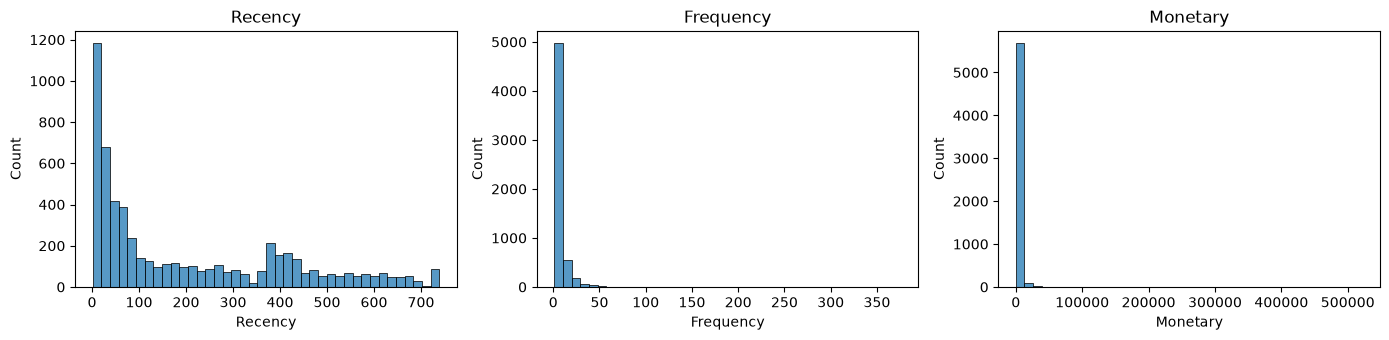

In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [15]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
rfm_scaled = StandardScaler().fit_transform(rfm_log)

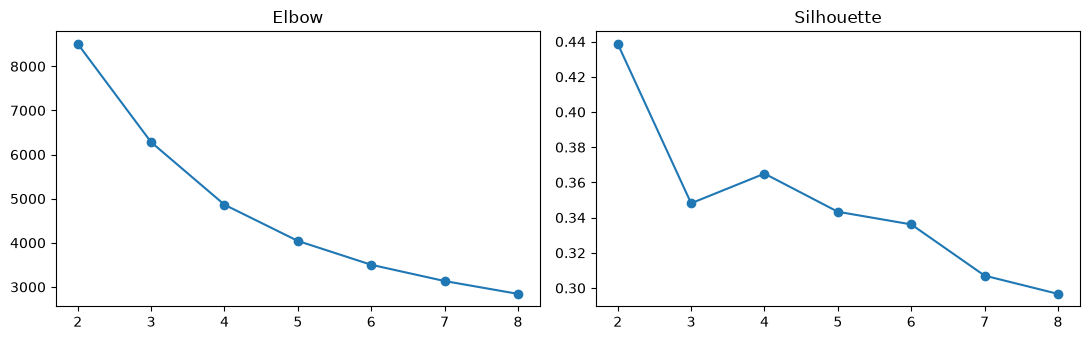

In [16]:
#group k shi ginti dhondo (elbow or silhouette)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_title("Elbow")
axes[1].plot(list(ks), sils, marker="o")
axes[1].set_title("Silhouette")
plt.tight_layout()
plt.show()

In [17]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = km.fit_predict(rfm_scaled)

summary = rfm.groupby("Cluster").agg(
    Customers=("Customer ID", "count"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
).round(1)
summary

,Customers,Recency,Frequency,Monetary
Cluster,,,,
0,1460,185.0,4.0,1419.6
1,1254,24.0,3.0,725.8
2,1937,402.0,1.0,266.4
3,1189,17.0,13.0,4909.7


In [18]:
segment_names = {3: "Champions", 1: "Loyal", 0: "At Risk", 2: "Lost"}
rfm["Segment"] = rfm["Cluster"].map(segment_names)
rfm["Segment"].value_counts()

Segment
Lost         1937
At Risk      1460
Loyal        1254
Champions    1189
Name: count, dtype: int64

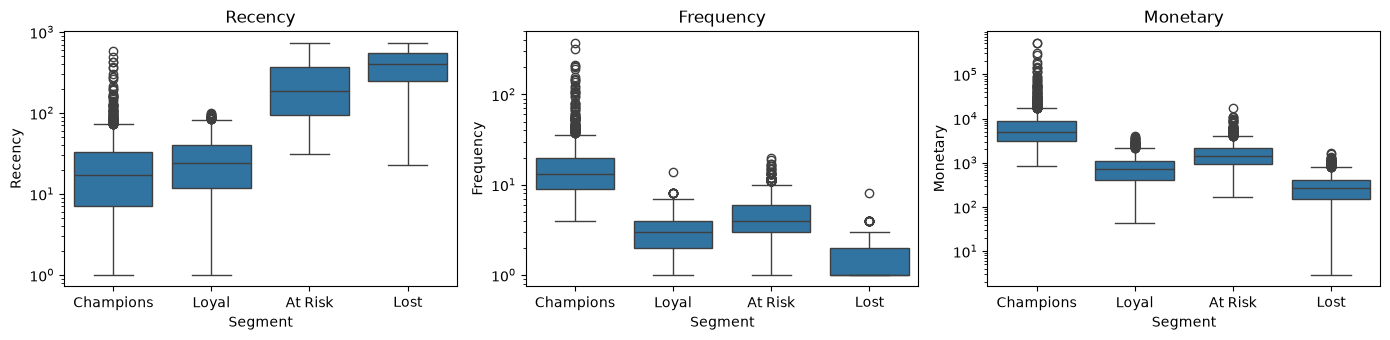

In [19]:
order = ["Champions", "Loyal", "At Risk", "Lost"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=rfm, x="Segment", y=col, order=order, ax=ax)
    ax.set_yscale("log")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
rfm.to_csv("../data/processed/rfm_segments.csv", index=False)

In [ ]:
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

rfm = pd.read_csv("../data/processed/rfm_segments.csv")
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

scaler = StandardScaler().fit(rfm_log)
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(scaler.transform(rfm_log))

# Check: naye clusters purane clusters ke barabar hone chahiye
print("Match with saved clusters:", (km.labels_ == rfm["Cluster"]).mean())

joblib.dump(scaler, "../models/rfm_scaler.joblib")
joblib.dump(km, "../models/kmeans_rfm.joblib")

Match with saved clusters: 1.0


['D:/Internship/Lens-customeriq/models/kmeans_rfm.joblib']